# Inference-only standardization: n=10 vs n=100

Compare inference-only standardization at n=10 (left) and n=100 (right),
using the layout of `baseline_vs_standardization_n100.ipynb`.
S=4D plots appear first, followed by S=2D. Each pair retains L2 and Density
diagnostics, the three error metrics, M1–M12 source colors, and circle markers.
Corresponding panels share x-axis limits; each metric uses a common y-axis
range across both sample sizes and summary dimensions.
The two sample sizes use their own simulated datasets and gold standards.


In [1]:
from io import BytesIO
from importlib import reload
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from PIL import Image as PILImage

ROOT = next(p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
            if (p / "examples/gaussian/config.py").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Pick up edits to plot.py when rerunning this notebook in an existing kernel.
from examples.gaussian.analysis import plot
reload(plot)
from examples.gaussian.analysis.plot import KEYS, load_runs, plot_metric_grid

RESULT_DIR = ROOT / "examples/gaussian/results"
INFERENCE_ONLY_DIR = RESULT_DIR / "ablation/inference_only"
NUM_OBS = (10, 100)  # Left, right.
SUMMARY_DIMS = (40, 80)
DIAGNOSTICS = ("l2", "density")
all_runs = {
    num_obs: load_runs("indirect", num_obs, summary_dims=SUMMARY_DIMS,
                       result_dir=INFERENCE_ONLY_DIR)
    for num_obs in NUM_OBS
}

# Compare gold standards across summary dimensions within each sample size.
# n=10 and n=100 have different observations and gold standards.
for num_obs, runs in all_runs.items():
    reference = runs["S=2D"].set_index(KEYS).sort_index()
    for frame in runs.values():
        aligned = frame.set_index(KEYS).sort_index()
        pd.testing.assert_frame_equal(
            reference[["gold_logml", "gold_pmp"]],
            aligned[["gold_logml", "gold_pmp"]], check_exact=True,
        )
    print(f"n={num_obs}: inference-only S=2D and S=4D dataset keys and gold standards match.")


n=10: inference-only S=2D and S=4D dataset keys and gold standards match.
n=100: inference-only S=2D and S=4D dataset keys and gold standards match.


In [2]:
# logML is plotted in log10 units. Cover both sample sizes and summary
# dimensions with one range, including all calibrated error thresholds.
logml_columns = ["signed_logml_error", "logml_error_lower", "logml_error_upper"]
logml_values = pd.concat(
    [frame[logml_columns] for runs in all_runs.values() for frame in runs.values()],
    ignore_index=True,
).to_numpy(float) / np.log(10.)
logml_min, logml_max = float(logml_values.min()), float(logml_values.max())
logml_ylim = (
    -10. ** np.ceil(np.log10(max(1., -logml_min))),
     10. ** np.ceil(np.log10(max(1., logml_max))),
)
Y_AXIS = {
    "posterior_mmd": dict(yscale="linear", ylim=(0., 1.5)),
    "logml": dict(yscale="symlog", linthresh=1., linscale=.9, ylim=logml_ylim),
    "pmp": dict(yscale="linear", ylim=(-1.05, 1.05)),
}
OUTPUT_DIR = RESULT_DIR / "plots/inference_only_n10_vs_n100"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def show_pair(metric, summary_dim=80):
    summary = {40: "2D", 80: "4D"}[summary_dim]
    run_label = f"S={summary}"
    output_dir = OUTPUT_DIR / f"s{summary.lower()}"
    output_dir.mkdir(parents=True, exist_ok=True)
    figures, panels = [], []
    try:
        for num_obs in NUM_OBS:
            fig, axes = plot_metric_grid(
                {run_label: all_runs[num_obs][run_label]}, metric,
                diagnostics=DIAGNOSTICS, color_by="source", source_marker="o",
                figsize=(14, 20), **Y_AXIS[metric],
            )
            figures.append((fig, axes))
            fig.suptitle(f"Inference-only standardization (n={num_obs})",
                         y=1.015, fontsize=24)

        # The two figures already share y-limits. Match each diagnostic's
        # x-limits using the union of their ranges, preserving all points.
        for column in range(len(DIAGNOSTICS)):
            limits = [axes[0, column].get_xlim() for _, axes in figures]
            common_xlim = (min(lo for lo, _ in limits), max(hi for _, hi in limits))
            for _, axes in figures:
                axes[0, column].set_xlim(common_xlim)

        for fig, _ in figures:
            with BytesIO() as buffer:
                fig.savefig(buffer, format="png", dpi=120, bbox_inches="tight")
                with PILImage.open(buffer) as image:
                    panels.append(image.convert("RGB"))

        with PILImage.new("RGB", (sum(p.width for p in panels) + 24,
                                  max(p.height for p in panels)), "white") as pair:
            x = 0
            for panel in panels:
                pair.paste(panel, (x, 0))
                x += panel.width + 24
            output = output_dir / f"inference_only_n10_vs_n100_{metric}.png"
            pair.save(output, dpi=(120, 120))
    finally:
        for fig, _ in figures:
            plt.close(fig)
        for panel in panels:
            panel.close()
    display(Image(filename=str(output), width=1400))
    print(f"Saved: {output}")


## S=4D

### Posterior MMD

#### n=10 (left) vs n=100 (right)

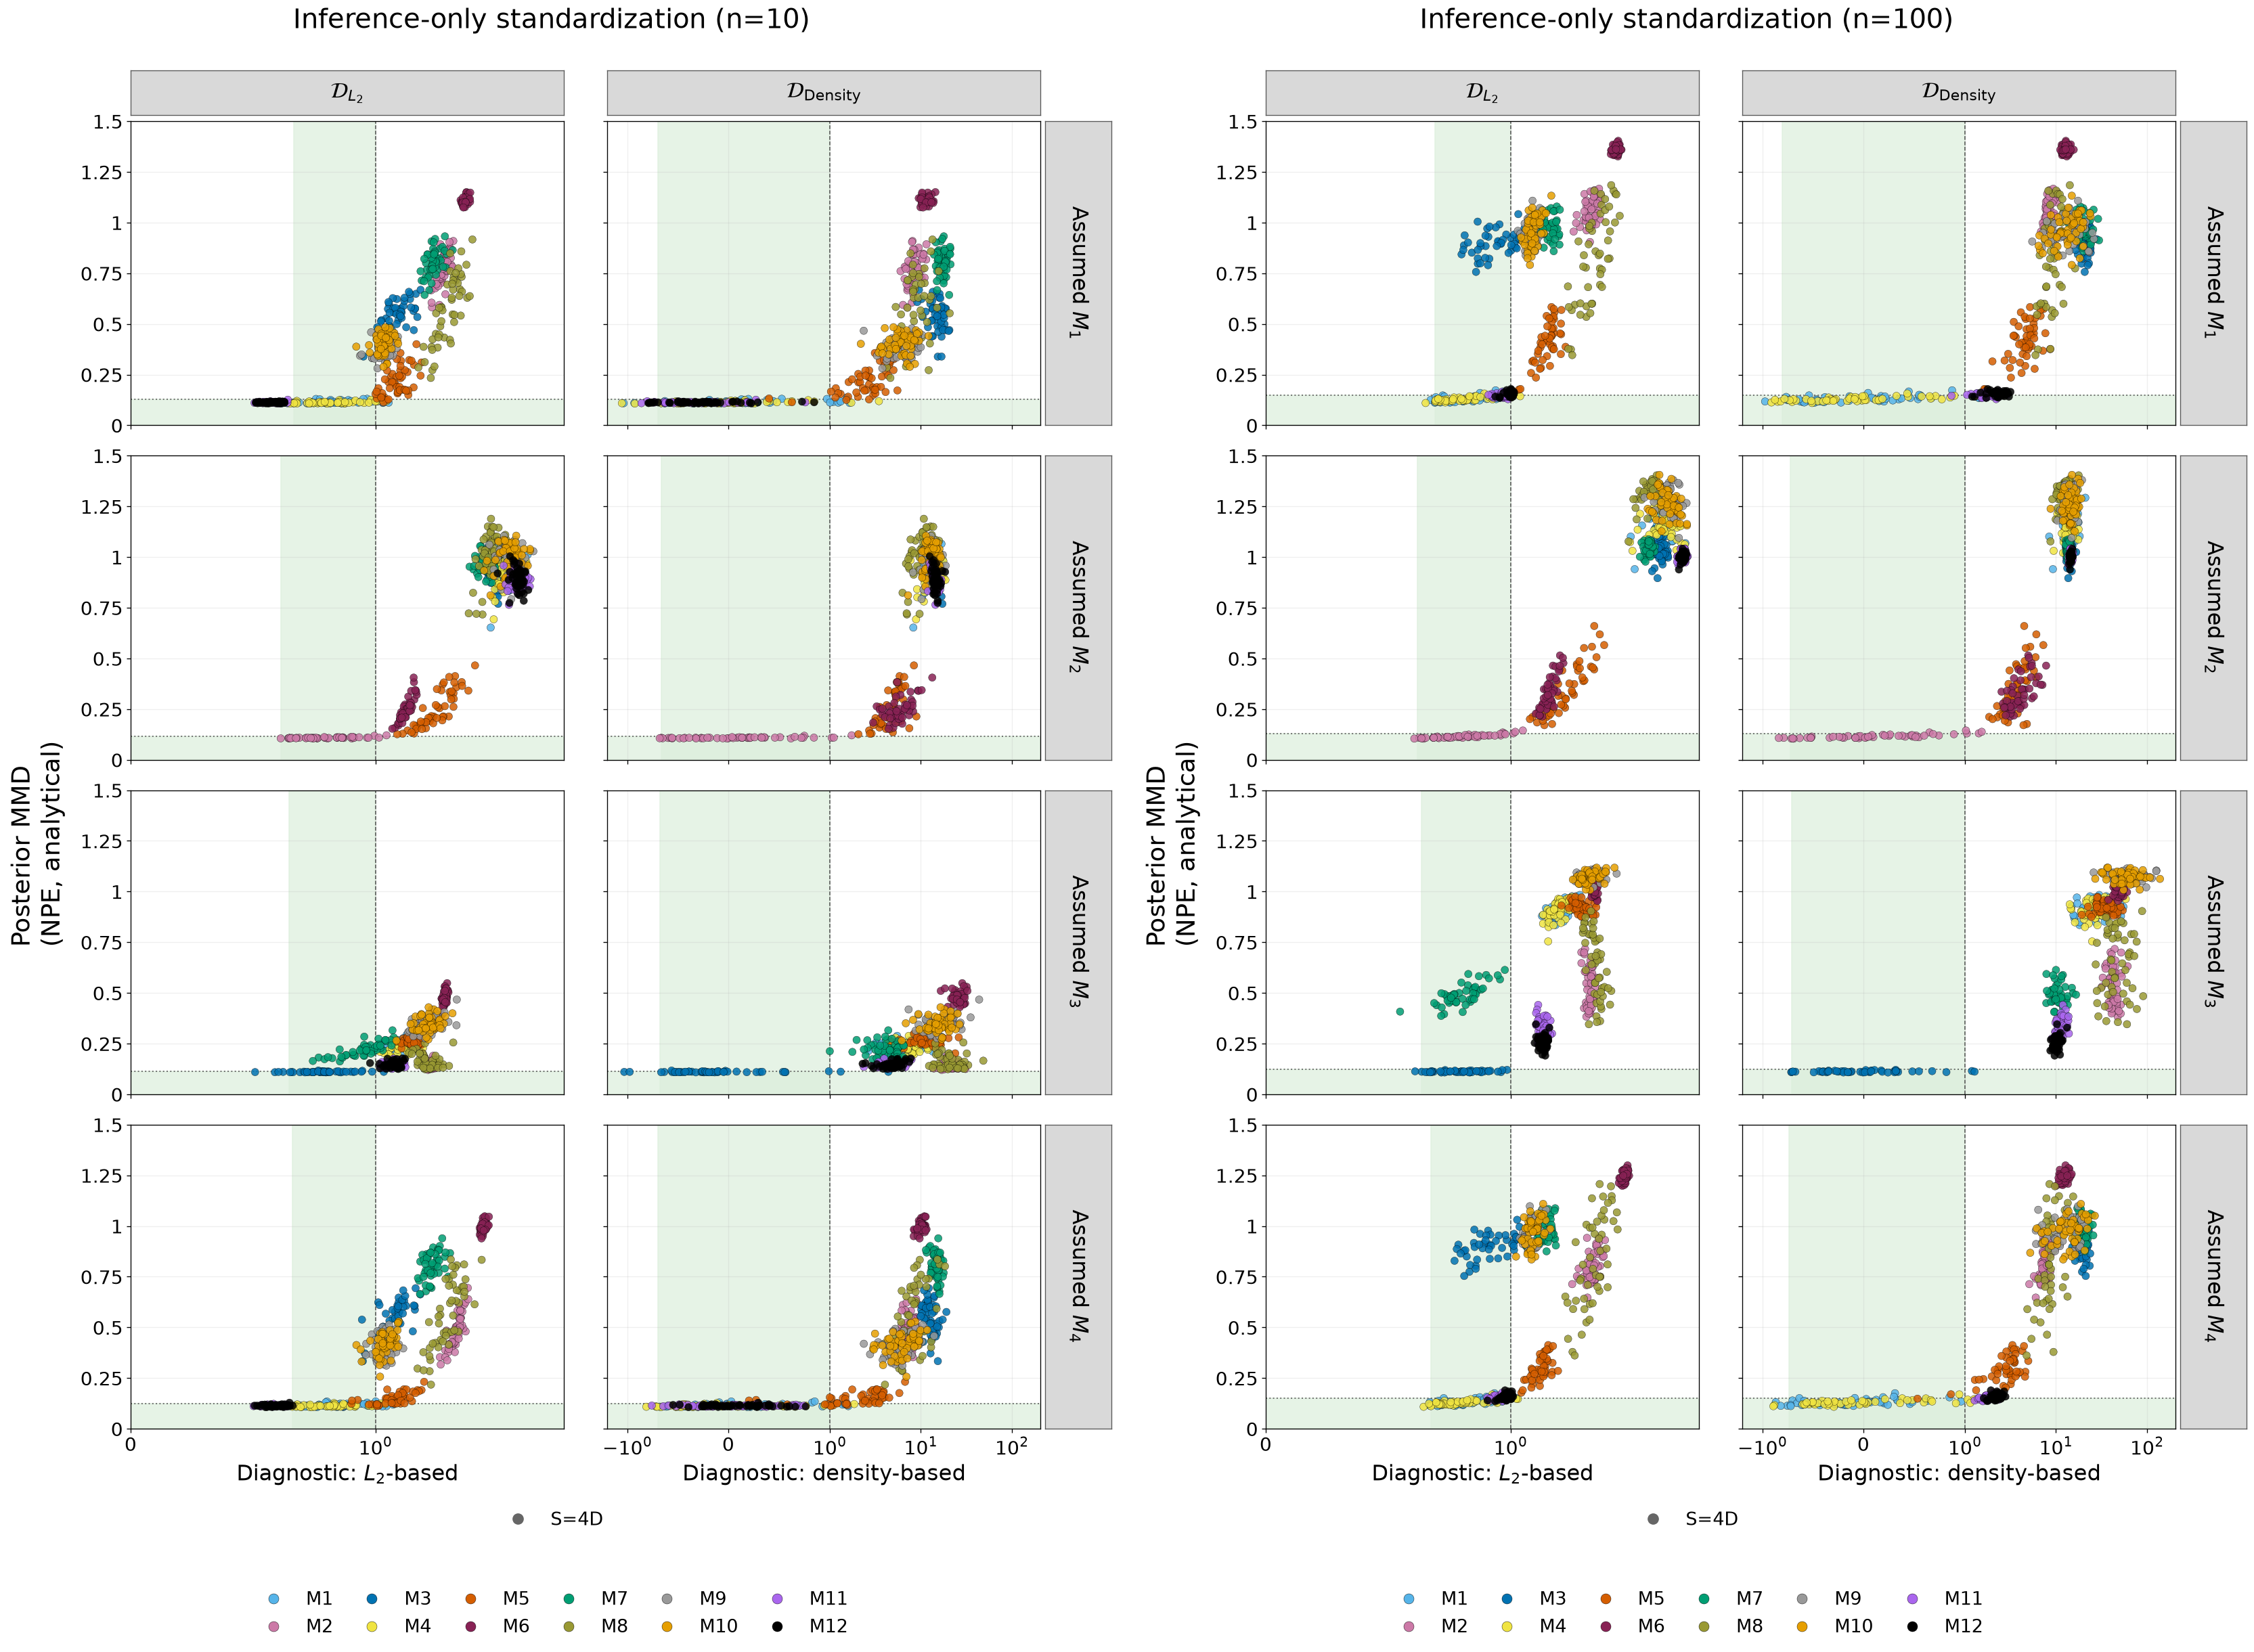

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s4d/inference_only_n10_vs_n100_posterior_mmd.png


In [3]:
show_pair("posterior_mmd")

### Log10 marginal-likelihood error

#### n=10 (left) vs n=100 (right)

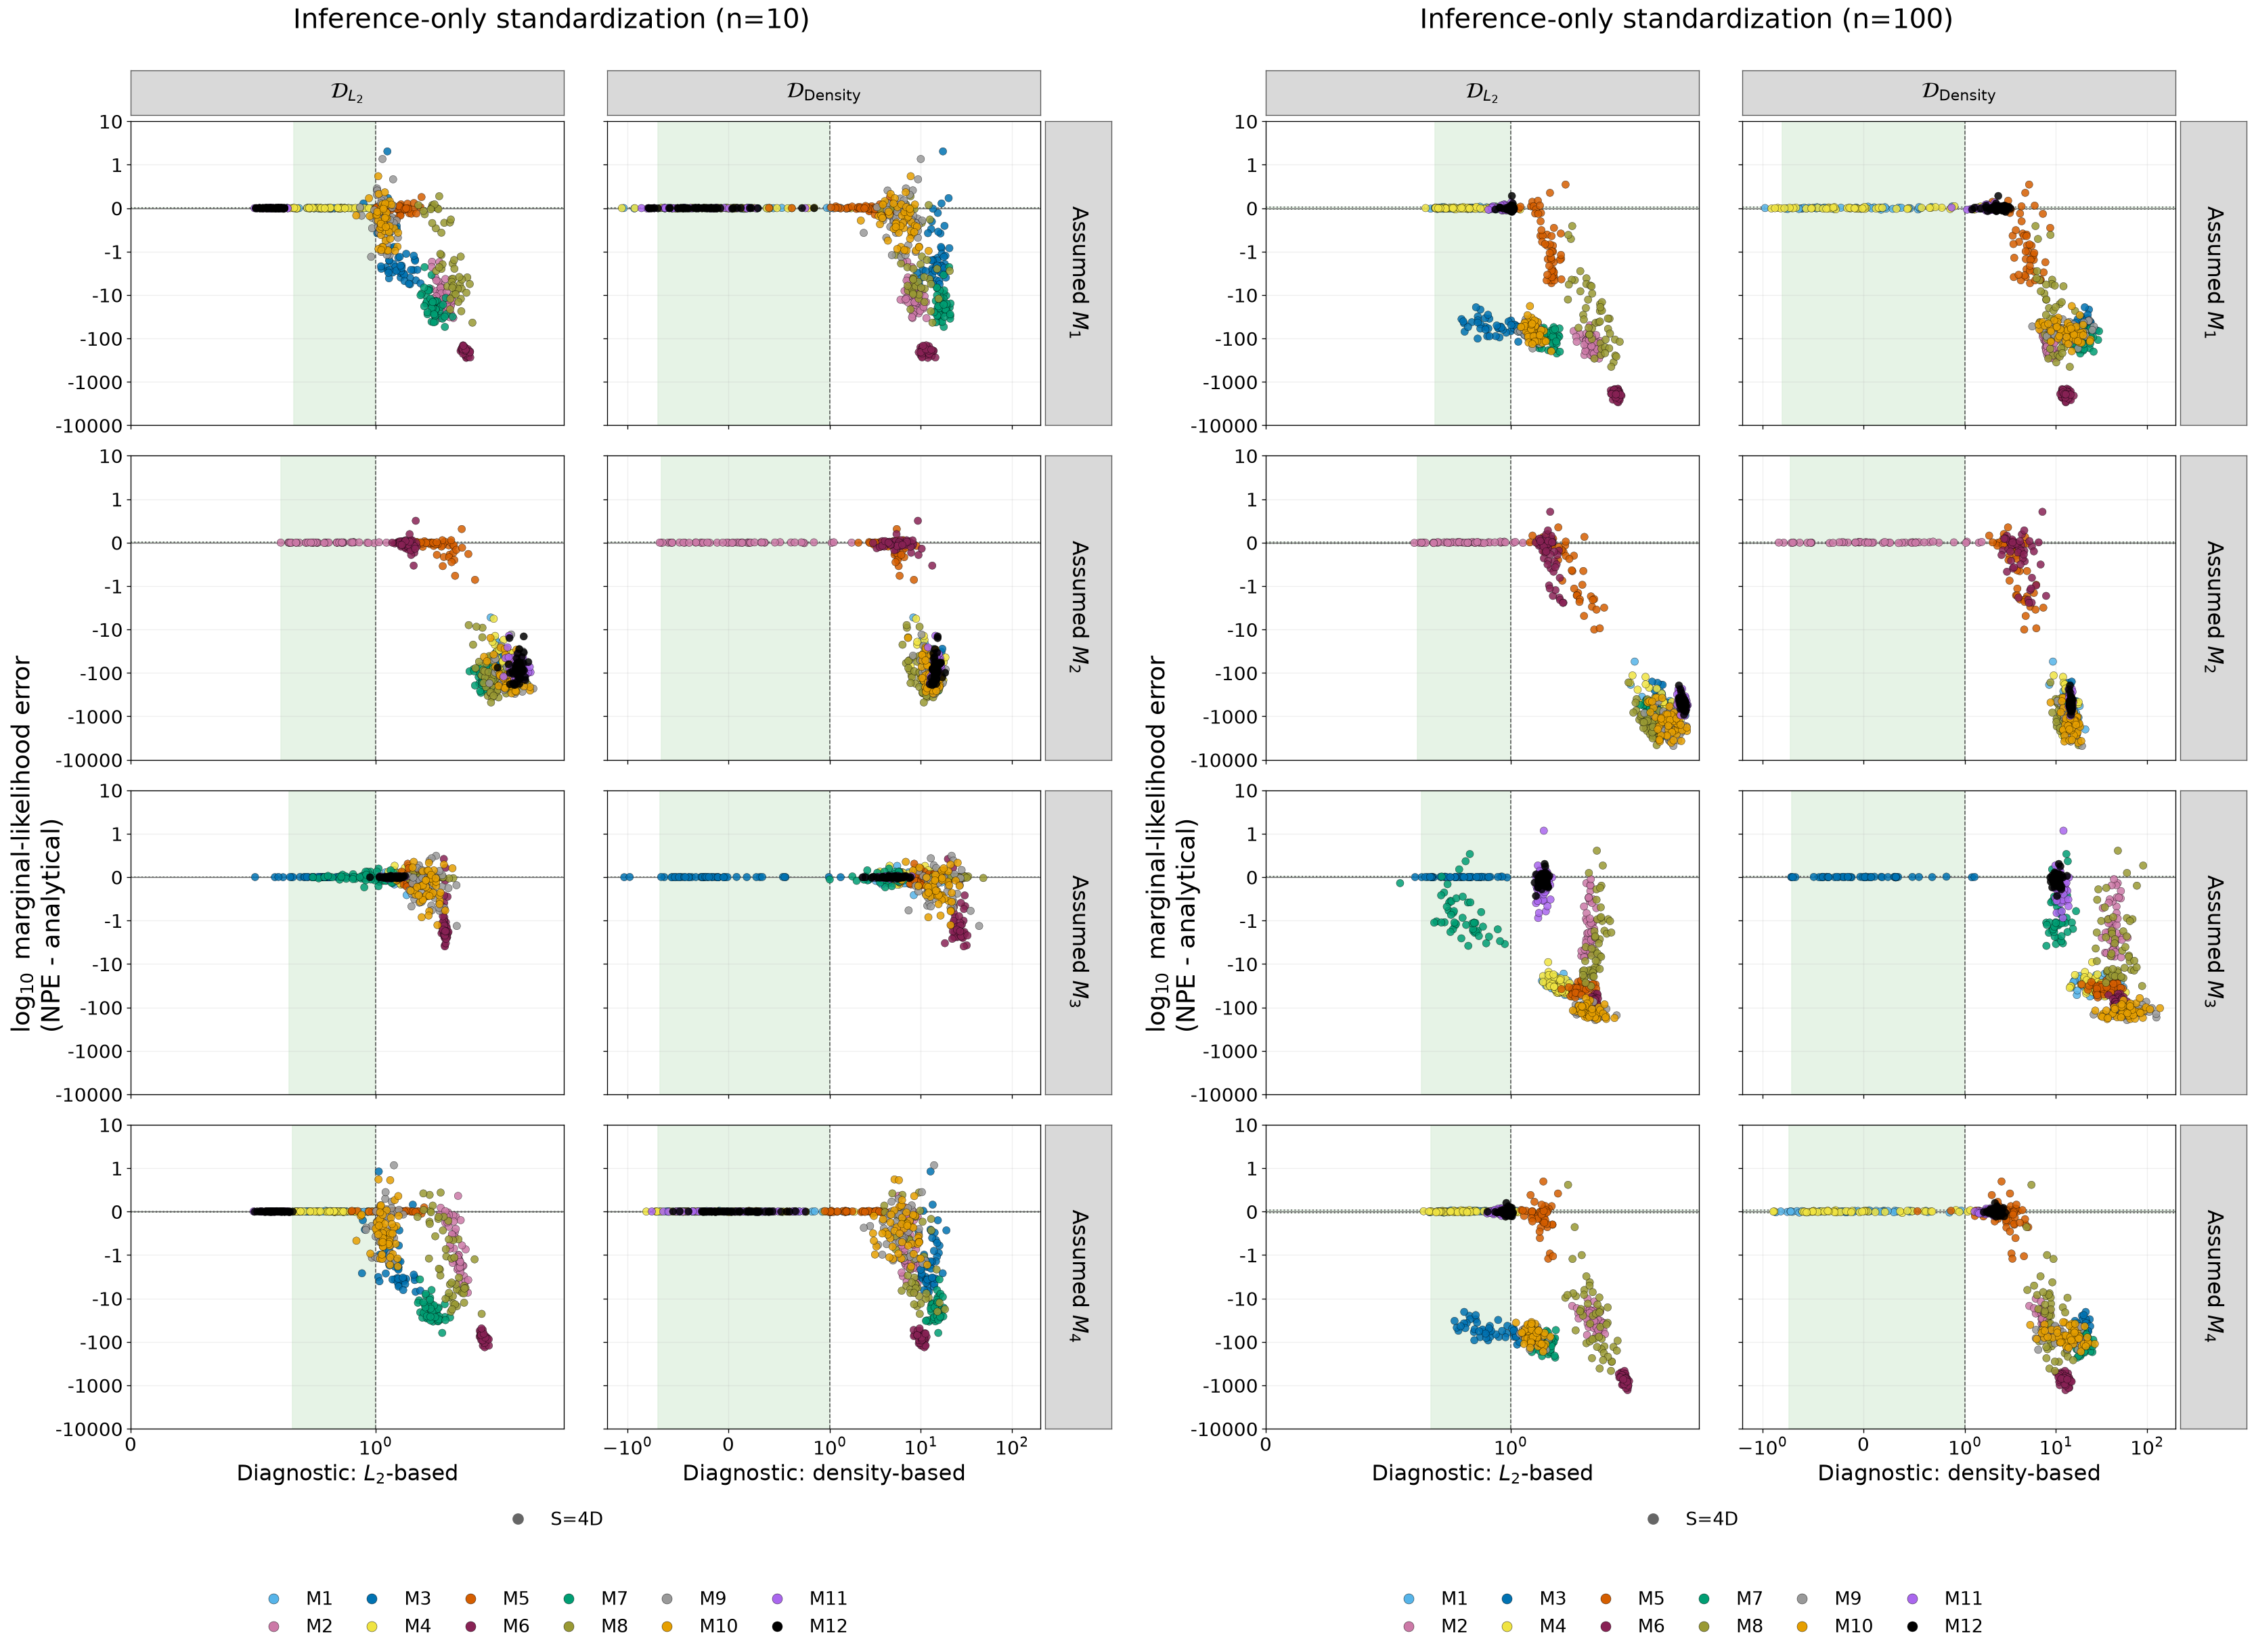

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s4d/inference_only_n10_vs_n100_logml.png


In [4]:
show_pair("logml")

### PMP error

#### n=10 (left) vs n=100 (right)

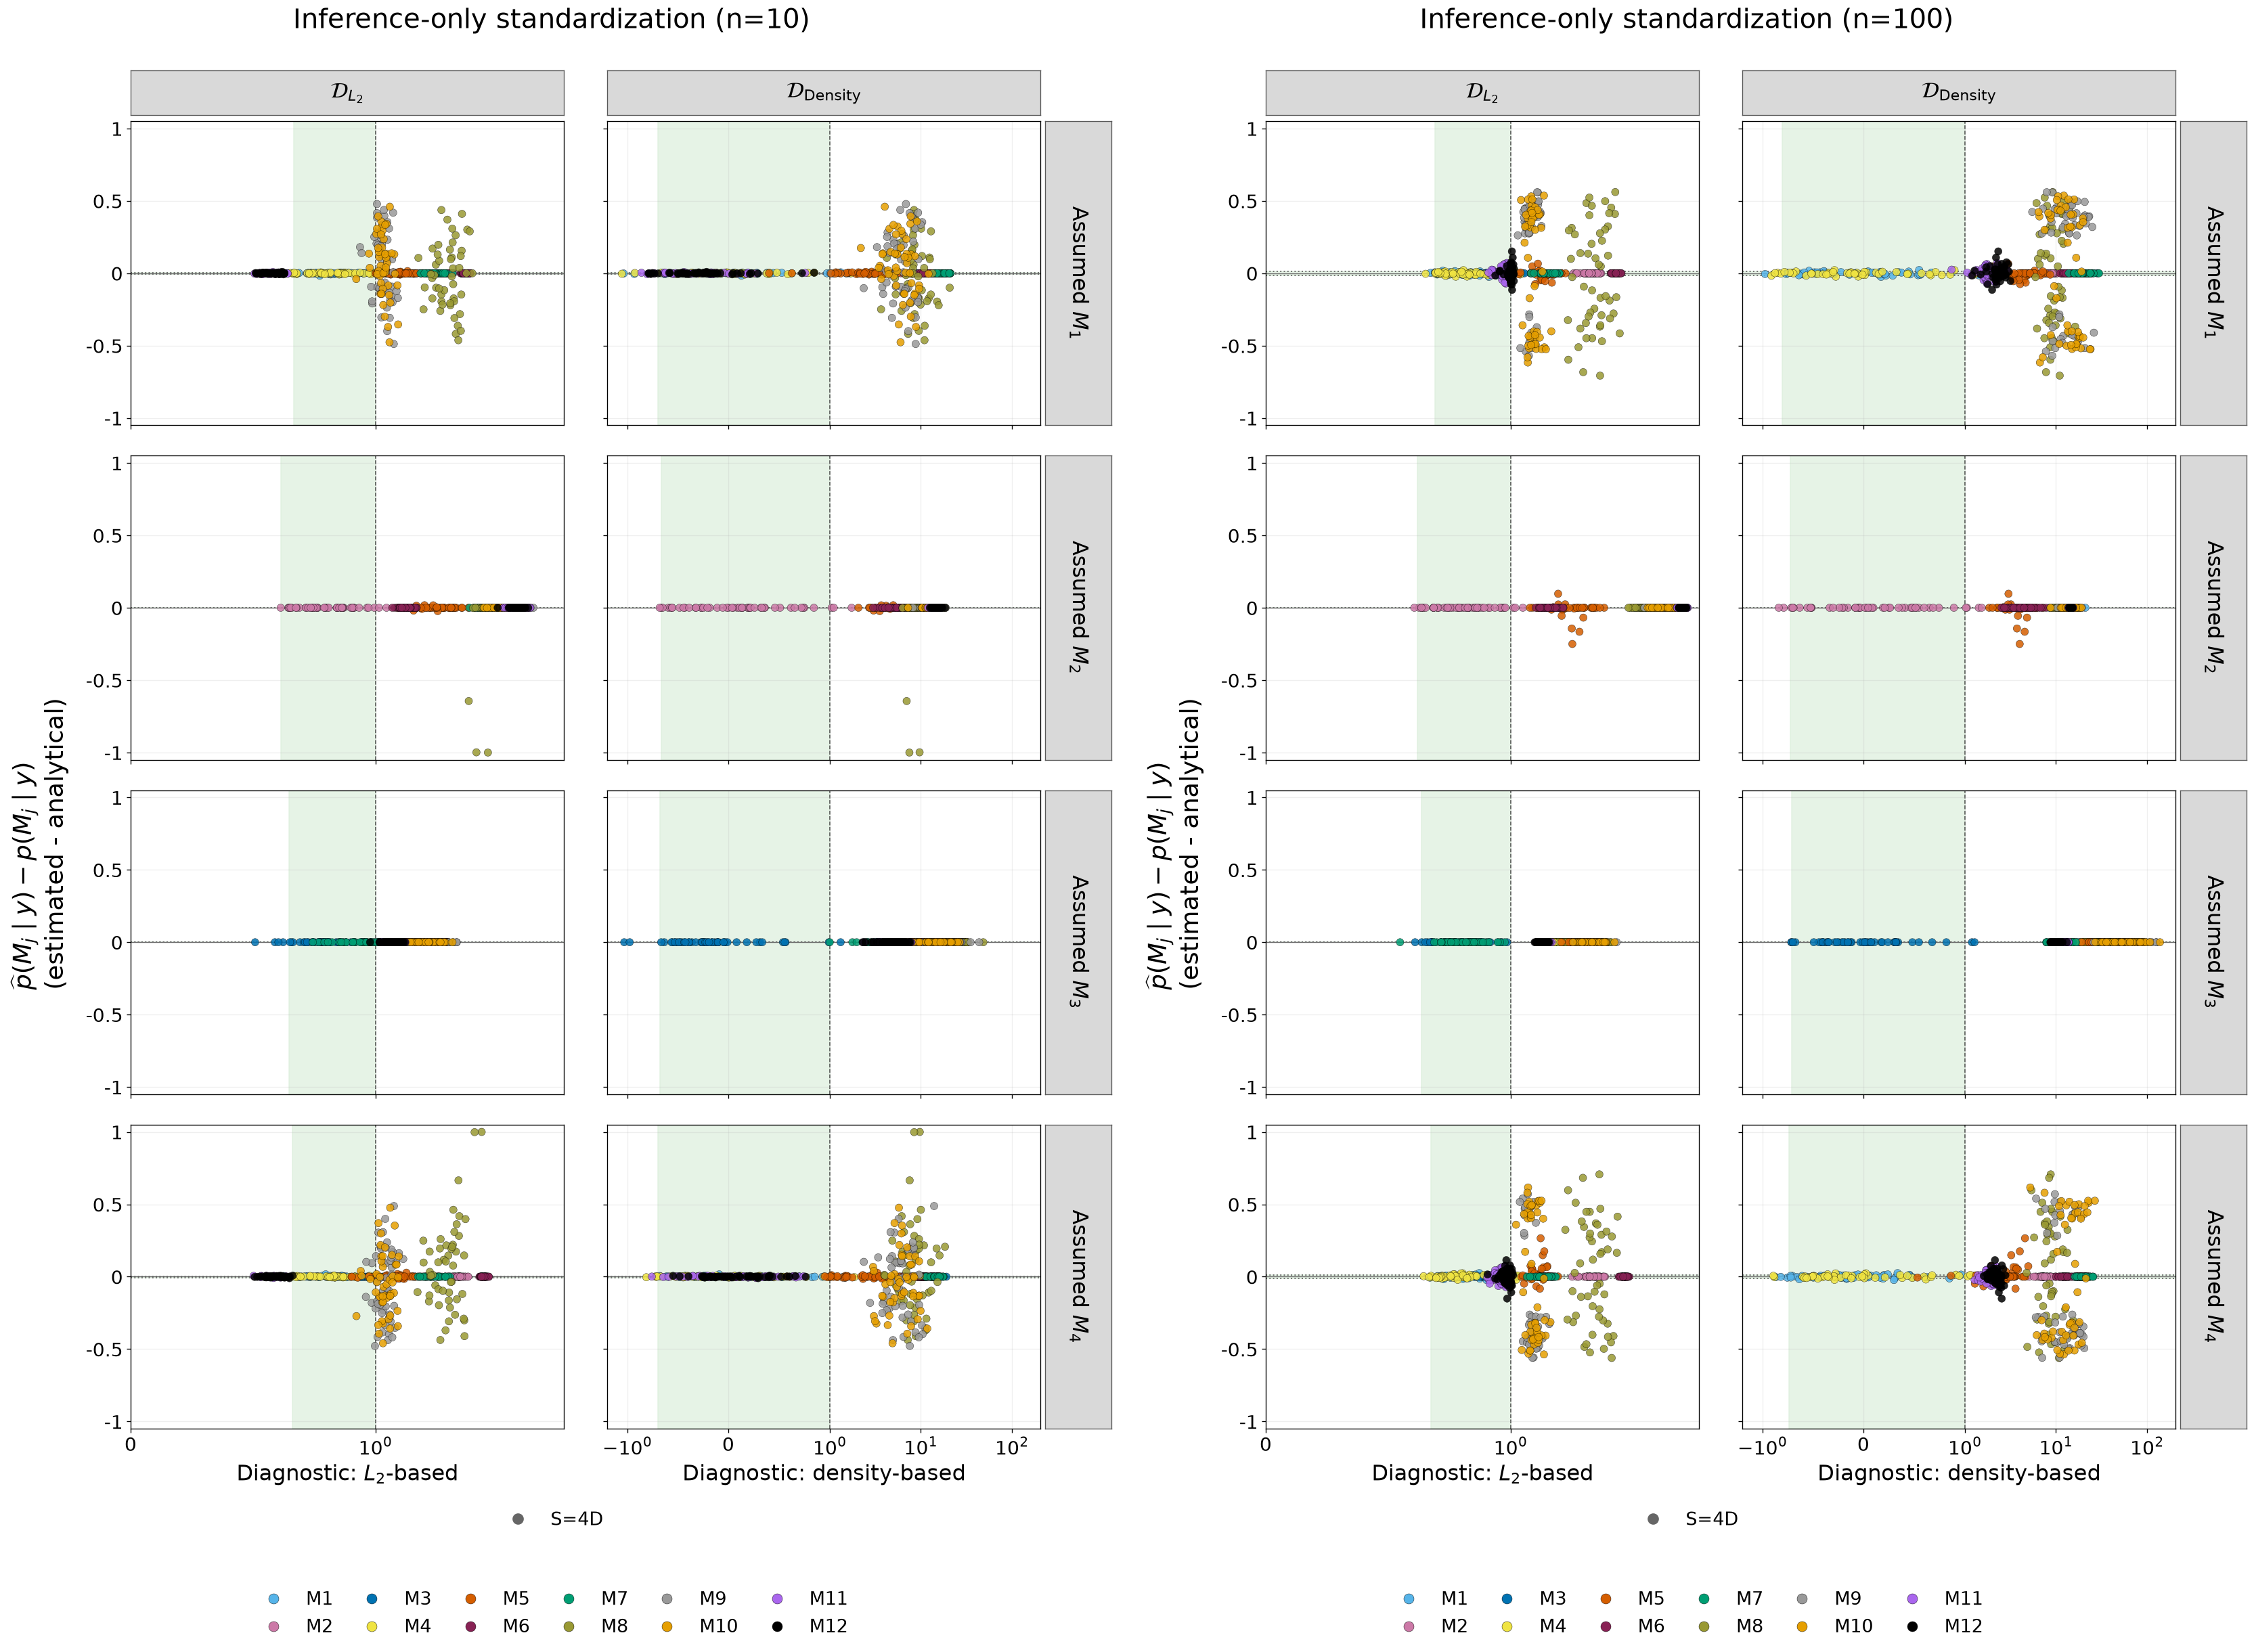

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s4d/inference_only_n10_vs_n100_pmp.png


In [5]:
show_pair("pmp")

## S=2D

### Posterior MMD

#### n=10 (left) vs n=100 (right)

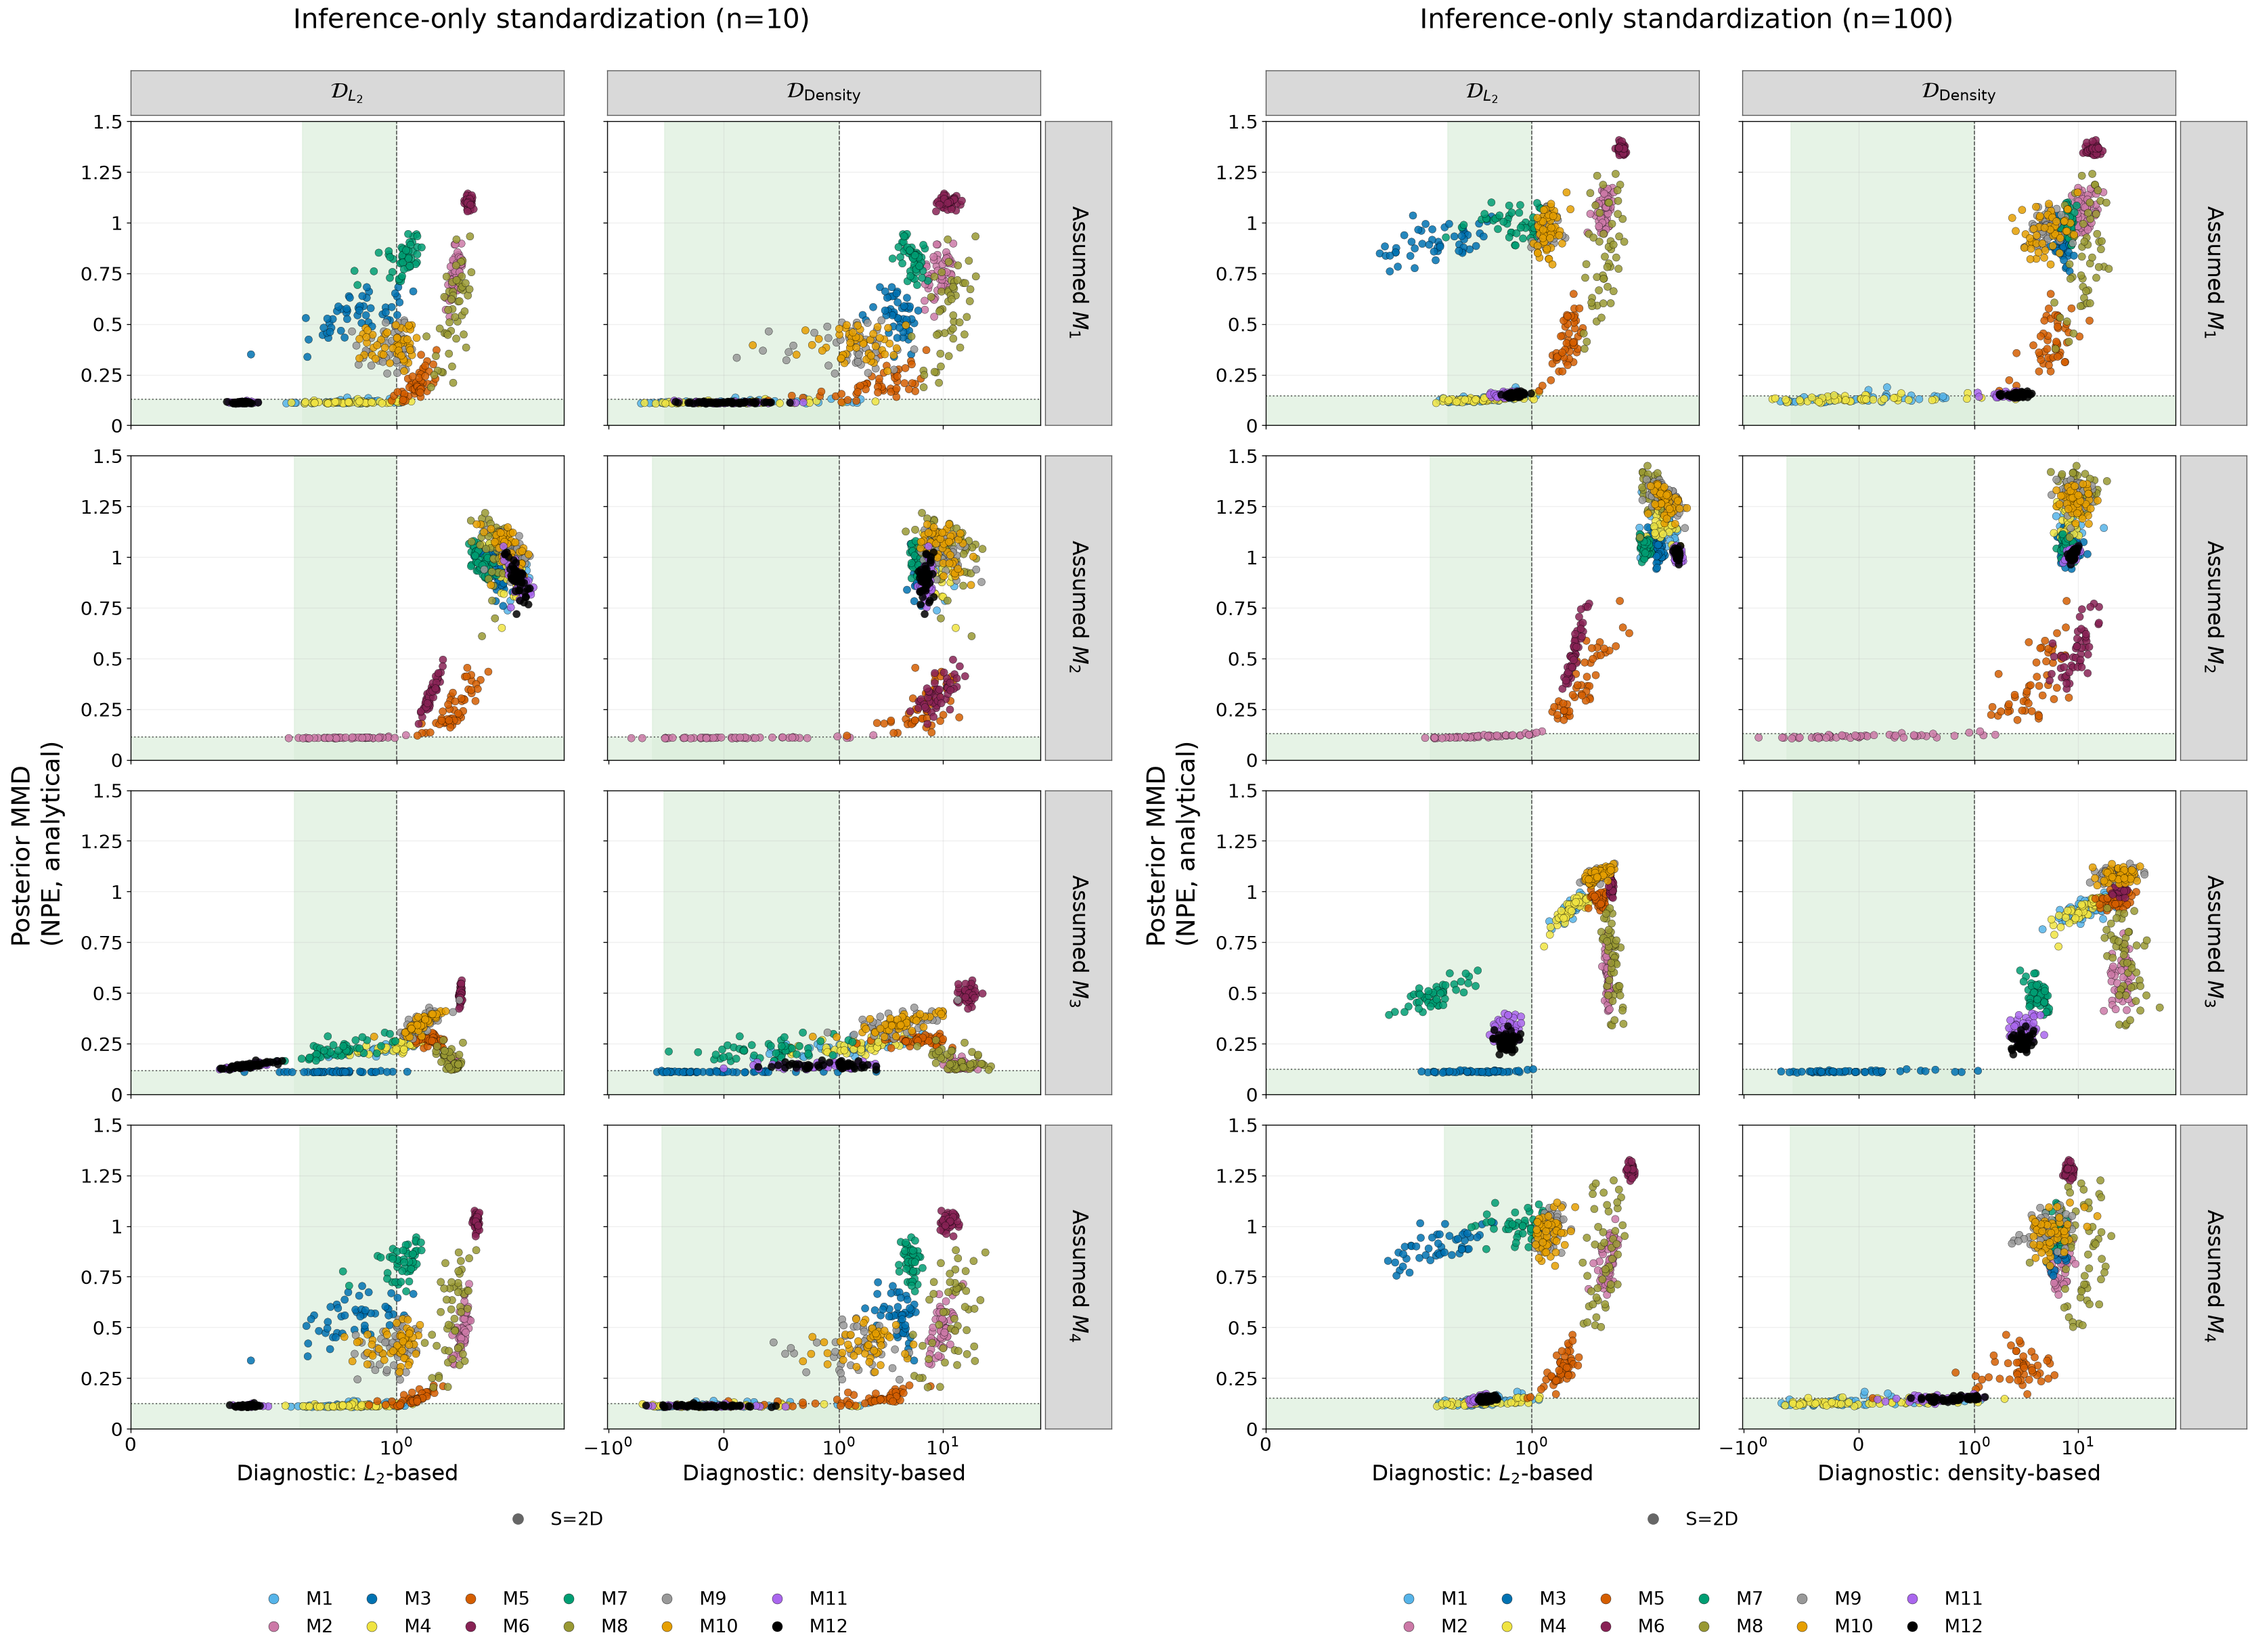

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s2d/inference_only_n10_vs_n100_posterior_mmd.png


In [6]:
show_pair("posterior_mmd", summary_dim=40)

### Log10 marginal-likelihood error

#### n=10 (left) vs n=100 (right)

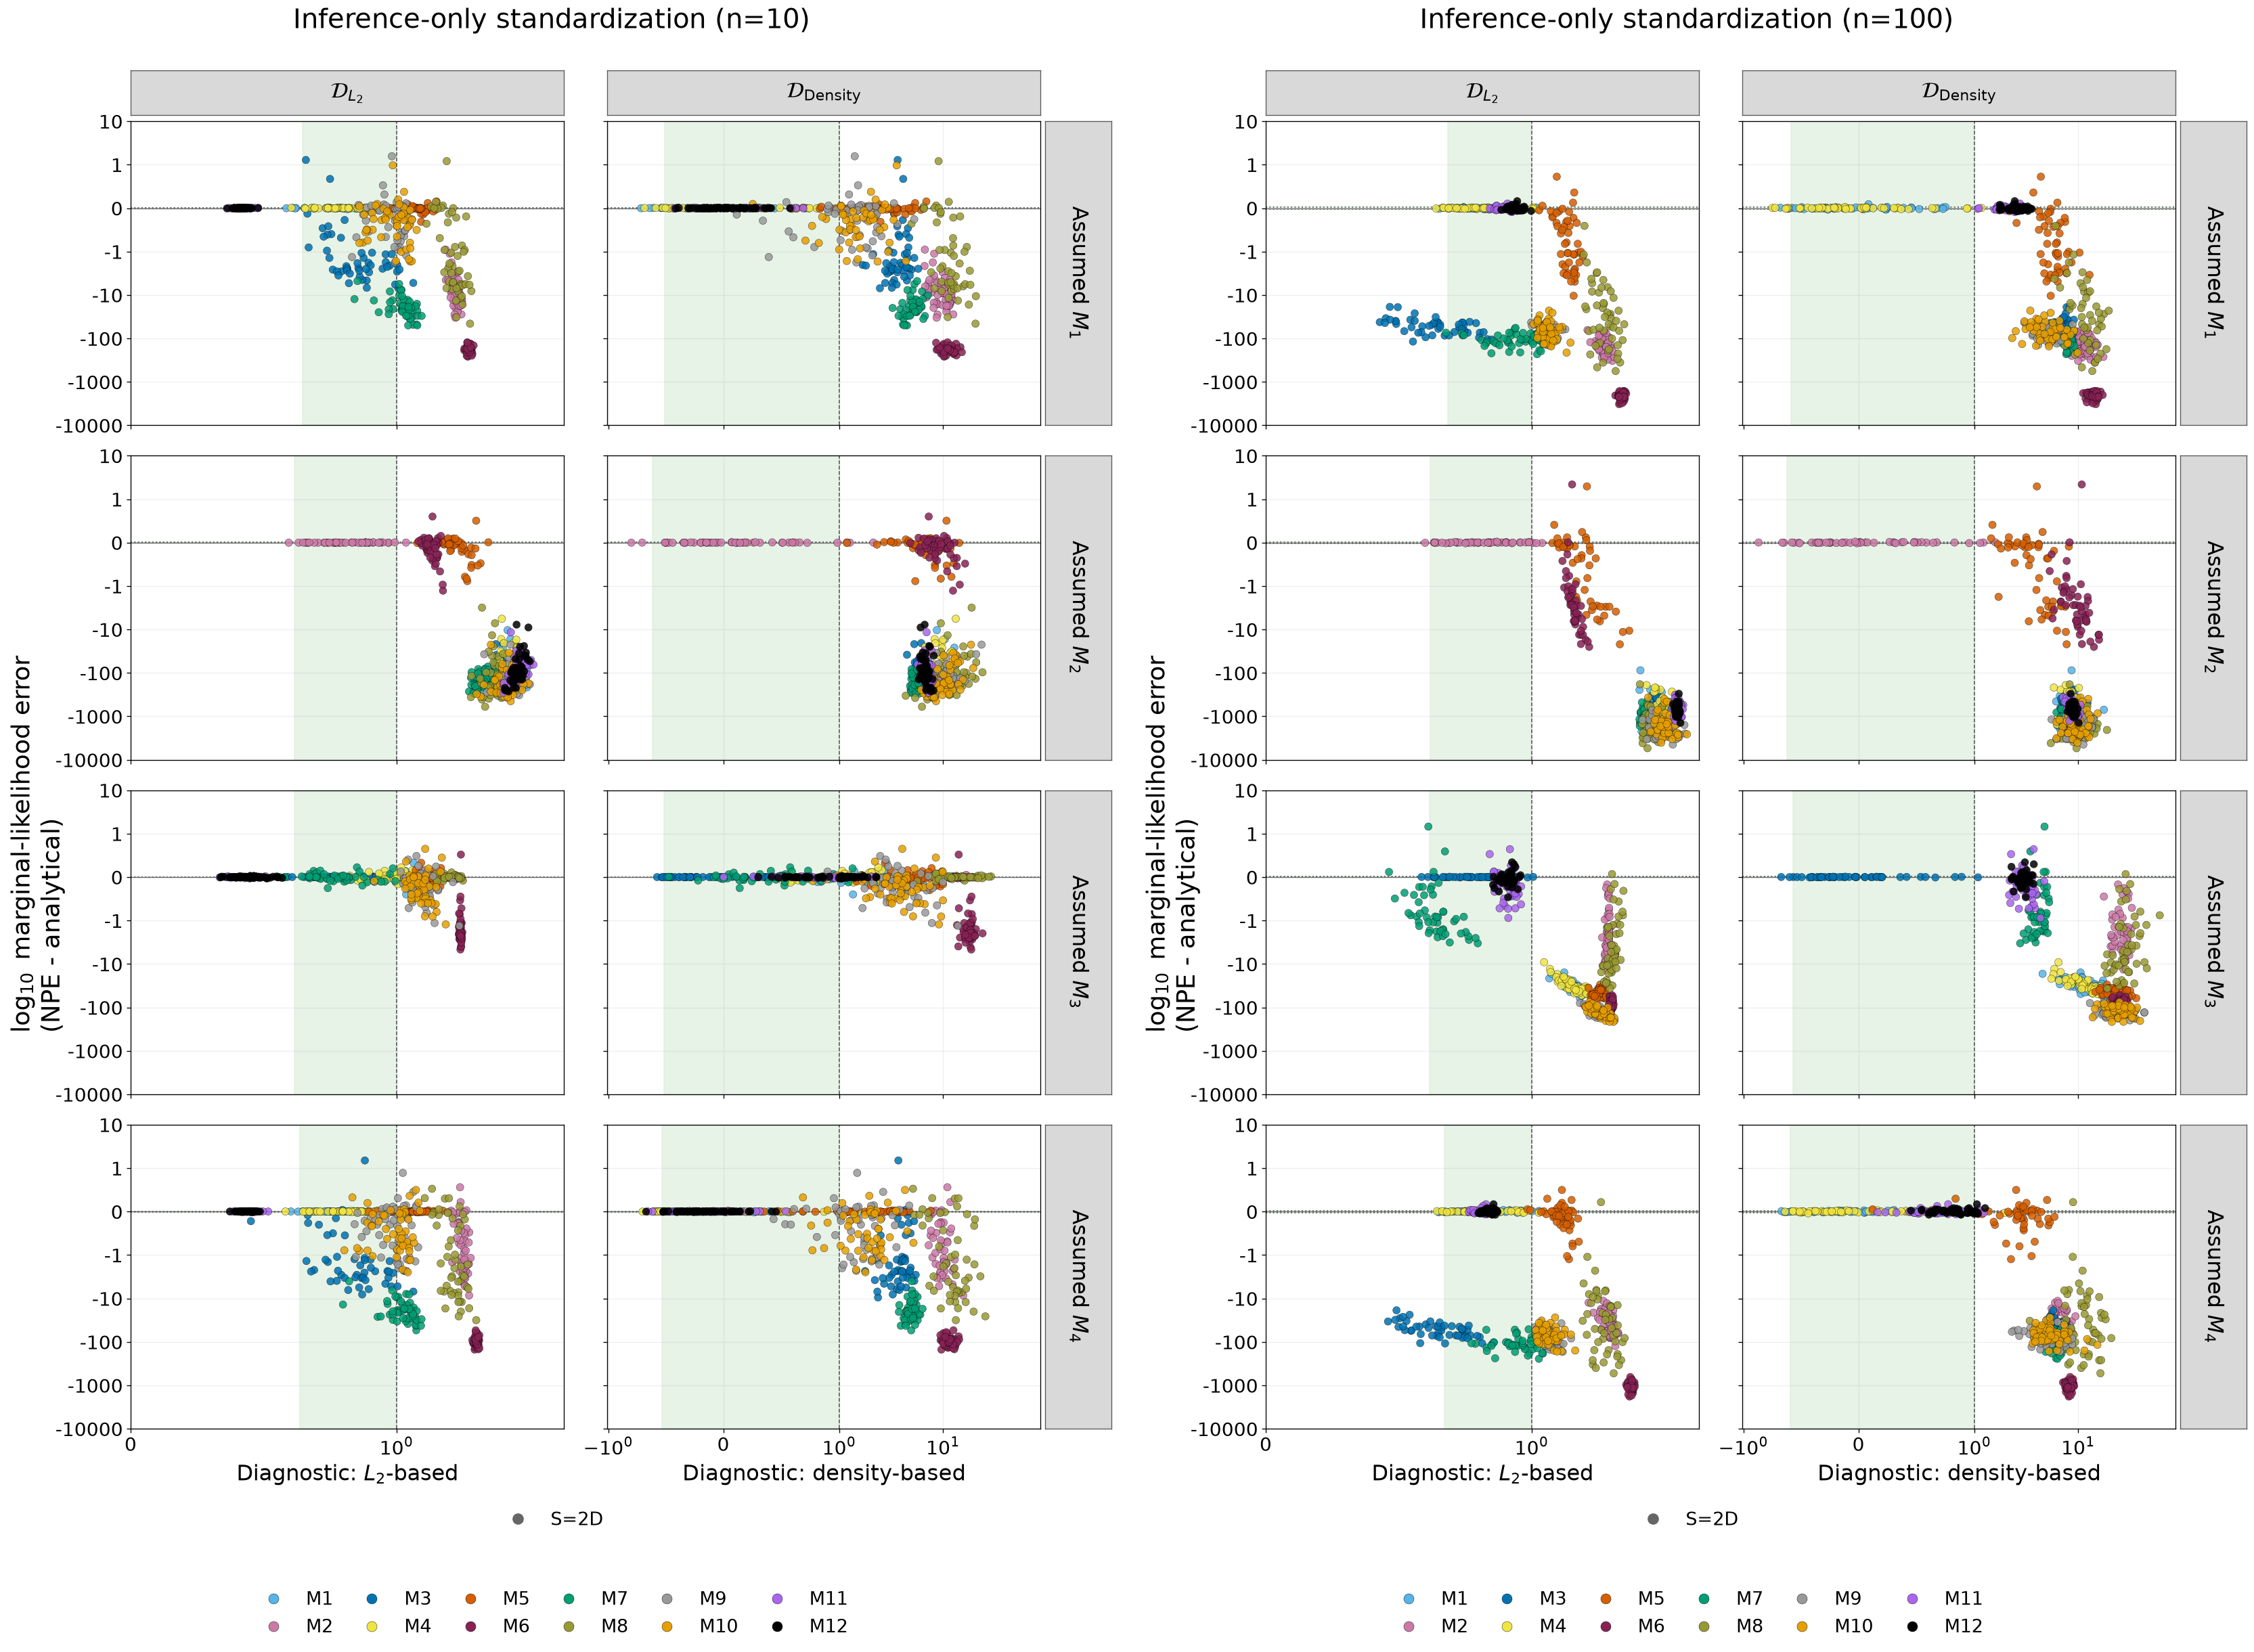

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s2d/inference_only_n10_vs_n100_logml.png


In [7]:
show_pair("logml", summary_dim=40)

### PMP error

#### n=10 (left) vs n=100 (right)

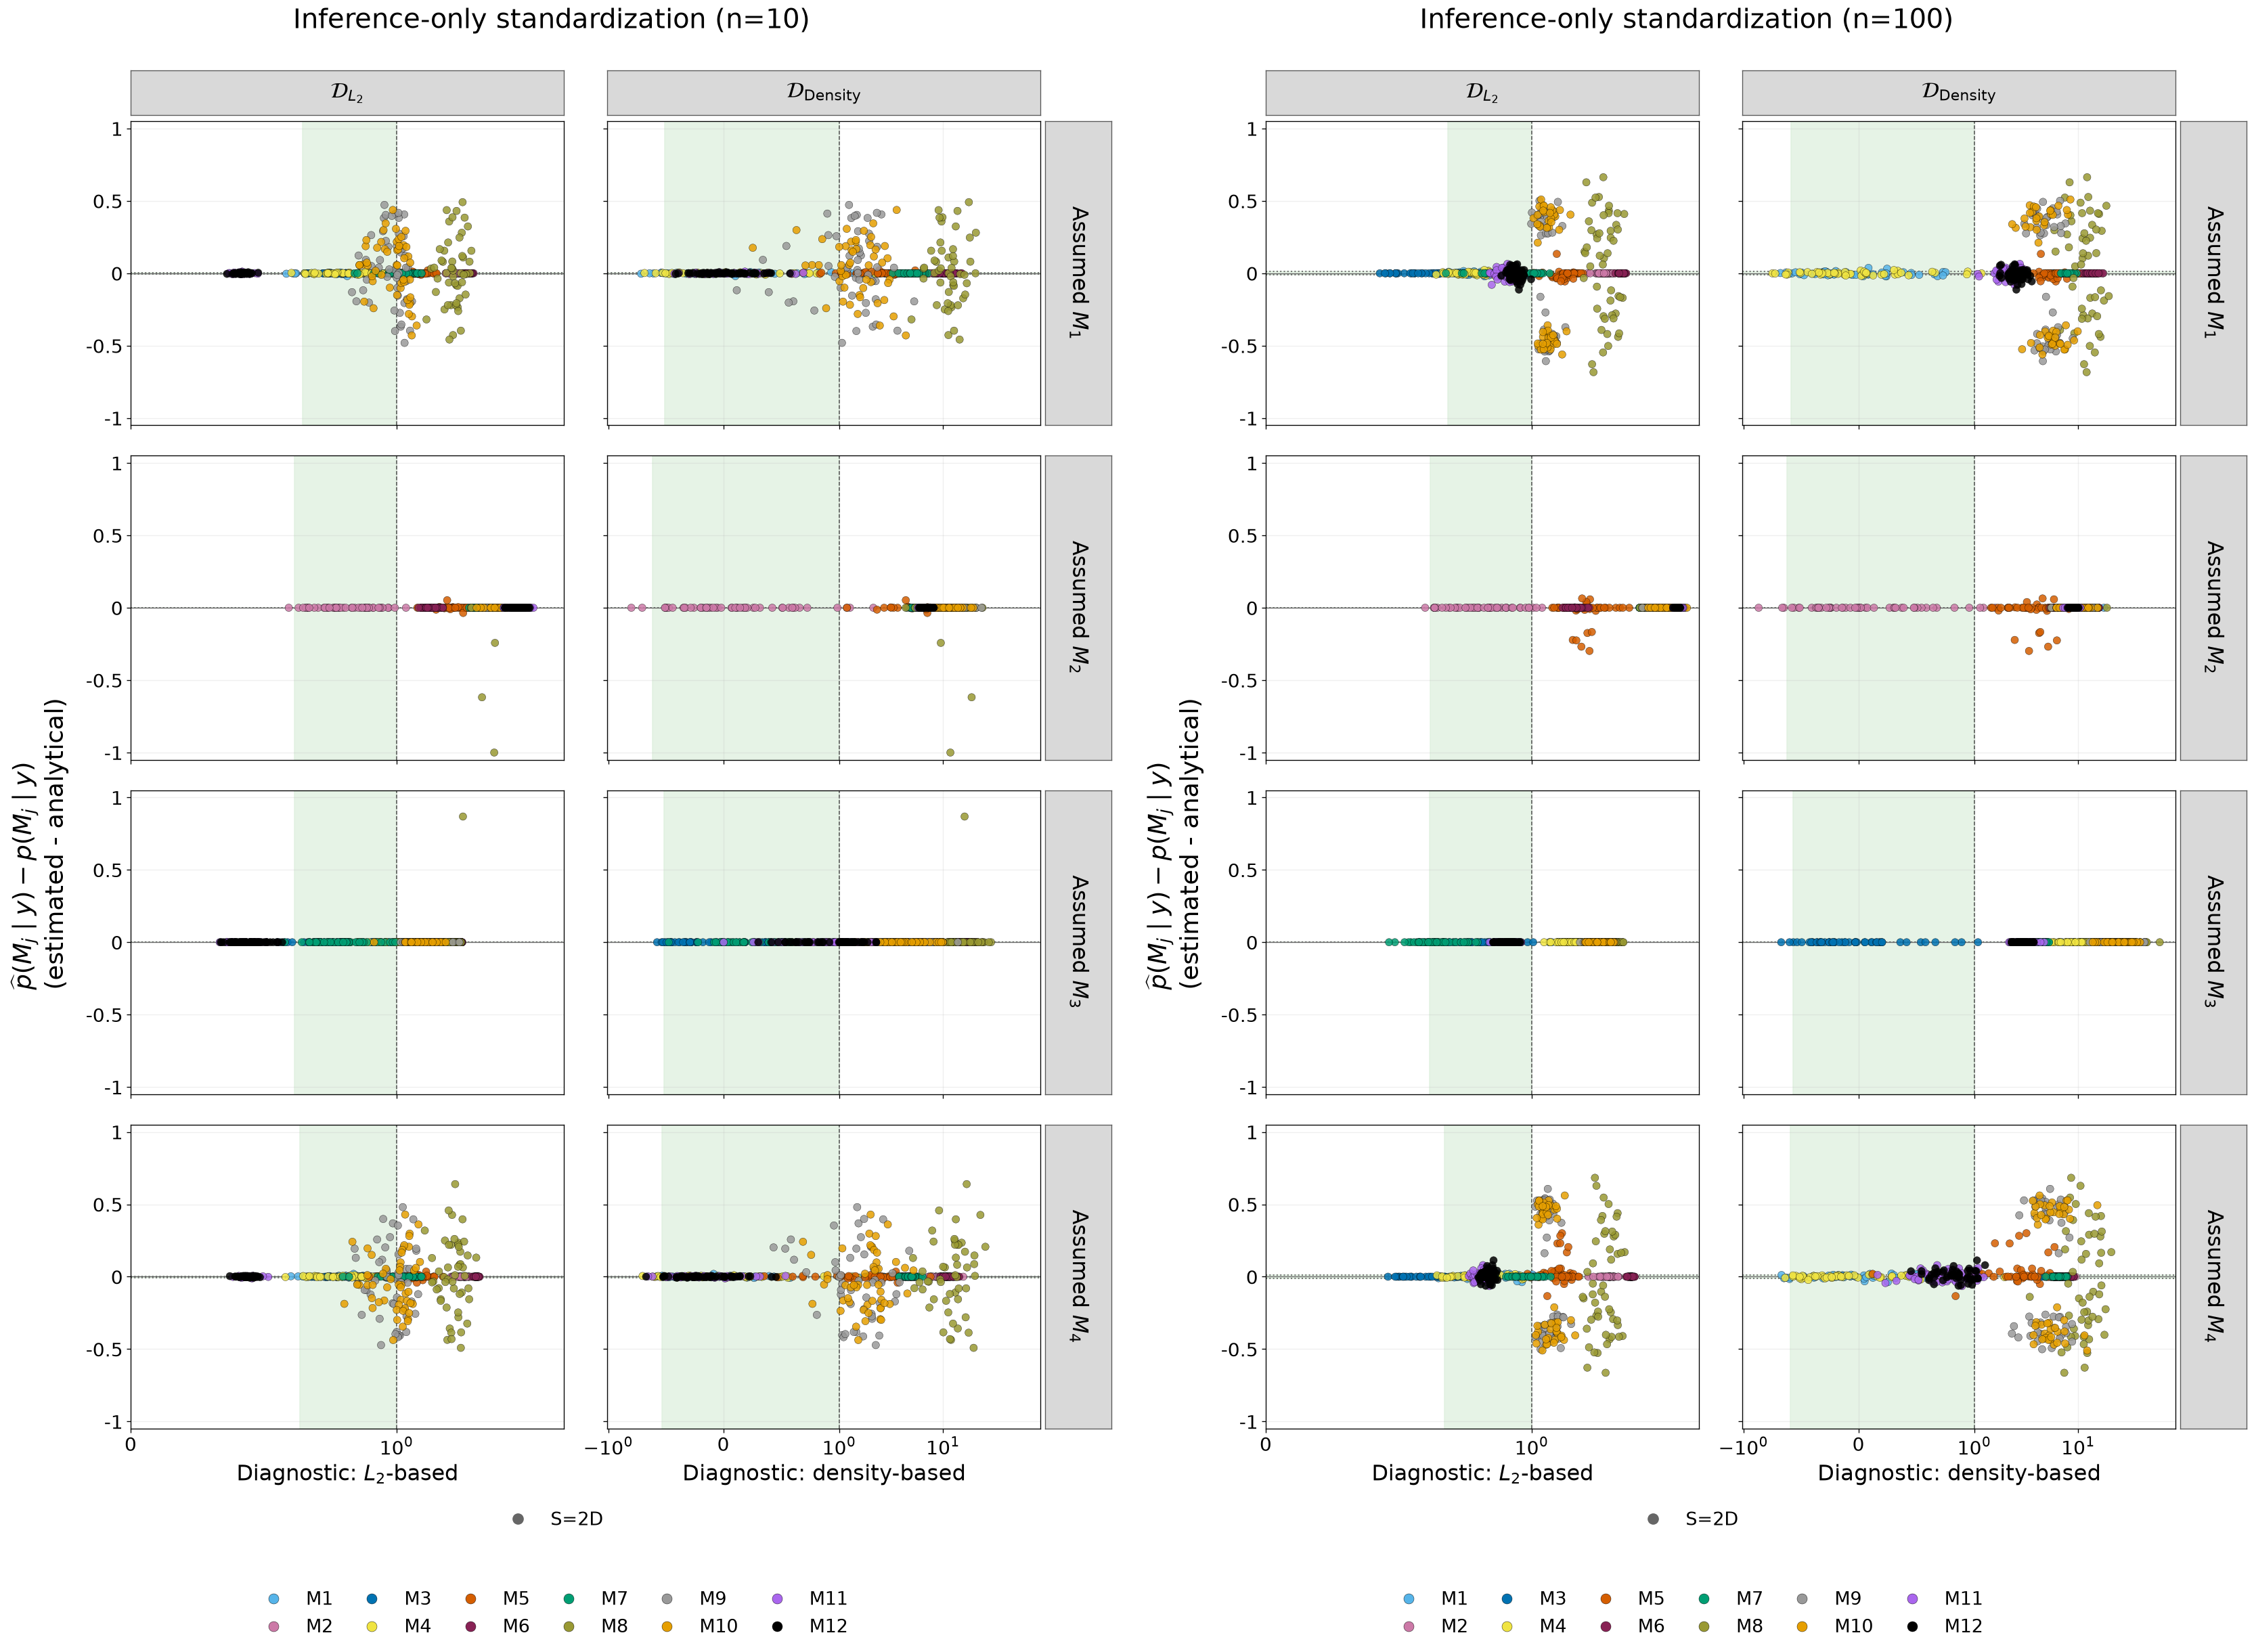

Saved: /Users/yimingzang/Documents/Project/model_comparison/examples/gaussian/results/plots/inference_only_n10_vs_n100/s2d/inference_only_n10_vs_n100_pmp.png


In [8]:
show_pair("pmp", summary_dim=40)